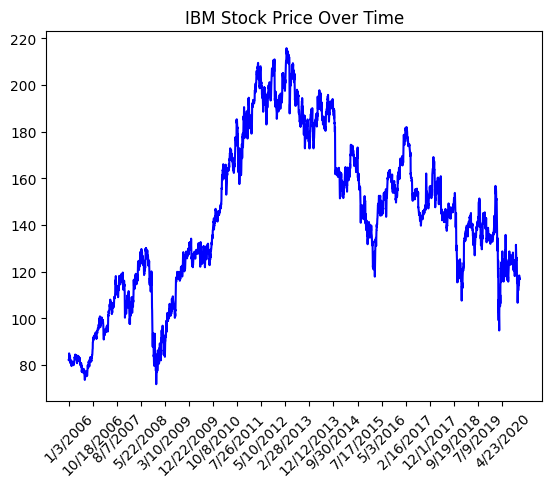

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
ibm = pd.read_csv('IBM.csv')
t = list(ibm['Date'])
plt.plot(ibm['Date'], ibm['Close'], color='blue', label='IBM Close Price')
plt.title('IBM Stock Price Over Time')
plt.xticks(t[0::200], rotation=45)
plt.show()

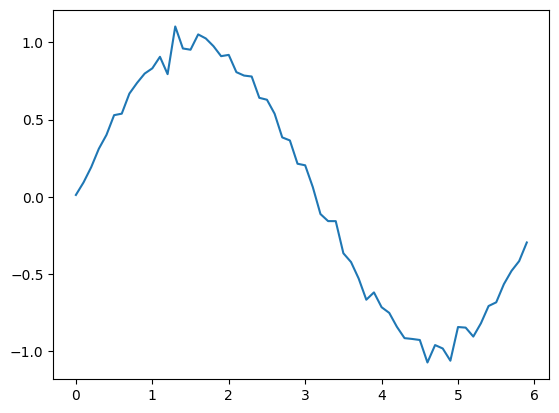

In [19]:
import numpy as np
#Creates an array of values from 0 to 6 with a step size of 0.1.
x = np.arange(0, 6, 0.1)
y = np.sin(x) + 0.05*np.random.randn(*x.shape)  # Sine wave with noise
plt.plot(x,y)
plt.show()


In [20]:

#to make central moving average to make the data set smoother:
def mov_avg(y,window_size):

    # Returns (centered) moving average of y using Pandas
    moving_averages = pd.Series(y).rolling(window_size,center=True).mean().tolist()
    y_mov = np.array(moving_averages).reshape(y.shape)

    return y_mov

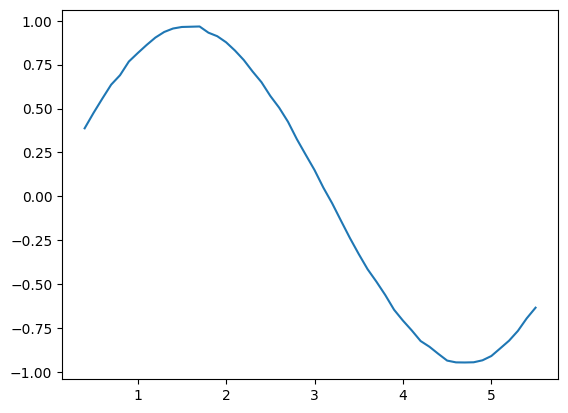

In [21]:
plt.plot(x,mov_avg(y,9))
plt.show()

In [23]:
!pip install yfinance
import yfinance as yf
from datetime import datetime


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 1.7/1.7 MB 24.2 MB/s  0:00:00

   ---------------------------------------- 0/9 [peewee]
   ---------------------------------------- 0/9 [peewee]
   ---------------------------------------- 0/9 [peewee]
   -------- ------------------------------- 2/9 [websockets]
   -------- ------------------------------- 2/9 [websockets]
   -------- ------------------------------- 2/9 [websockets]
   -------- ------------------------------- 2/9 [websockets]
   ------------- -------------------------- 3/9 [protobuf]
   ------------- -------------------------- 3/9 [protobuf]
   ------------- -------------------------- 3/9 [protobuf]
   ------------- -------------------------- 3/9 [protobuf]
   ------------- -------------------------- 3/9 [protobuf]
   ----------------- ---------------------- 4/9 [mdurl]
   ---------------------- ----------------- 5/9 [markdown-it-py]
   ----------------------

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.1.0)/charset_normalizer (3.4.0) doesn't match a supported version!
  warnings.warn(


In [24]:
end_date = datetime(year=2025, month=1, day=1)
start_date = datetime(year=2000, month=1, day=1)

df = yf.download(
tickers="AAPL",
start=start_date,
end=end_date,
interval="1d",
group_by="ticker",
auto_adjust=True,
progress=False

)
df.reset_index(inplace = True)

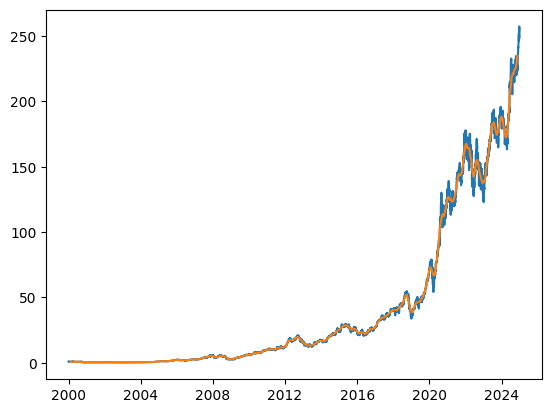

In [25]:
plt.plot(df['Date'],df["AAPL"]["Close"])
plt.plot(df['Date'],mov_avg(df["AAPL"]["Close"],60))
plt.show()

In [26]:
def find_peaks(y):
    return np.where(np.diff(1*(np.diff(y)>0))==-1)

In [27]:
def find_valleys(y):
    return np.where(np.diff(1*(np.diff(y)>0))==1)

In [28]:
y = df['AAPL']['Close'].rolling(window=180).mean()

peaks_pos = find_peaks(y)
valleys_pos = find_valleys(y)

In [29]:
print(np.max(np.diff(peaks_pos)))
print(np.max(np.diff(valleys_pos)))

1071
873


In [32]:
%pip install keras
%pip install tensorflow
import datetime
import sklearn

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import KernelPCA
import numpy as np
import pandas as pd
import math
import keras
import matplotlib.pyplot as plt
import tensorflow as tf
tf.random.set_seed(2025)
df = pd.read_csv('final_data_adj.csv')
dates = df.Date
df = df.set_index('Date')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/351.2 MB ? eta -:--:--
   ---------------------------------------- 2.6/351.2 MB 14.3 MB/s eta 0:00:25
    --------------------------------------- 5.2/351.2 MB 16.6 MB/s eta 0:00:21
   - -------------------------------------- 10.5/351.2 MB 17.3 MB/s eta 0:00:20
   - -------------------------------------- 17.3/351.2 MB 21.0 MB/s eta 0:00:16
   -- ------------------------------------- 22.0/351.2 MB 21.6 MB/s eta 0:00:16
   --- ------------------------------------ 26.7/351.2 MB 21.3 MB/s eta 0:00:16
   --- ------------------------------------ 32.5/351.2 MB 22.1 MB/s eta 0:00:15
   ---- ----------------------------------- 39.3/351.2 MB 23.4 MB/s eta 0:00:14
   ----- ---------------------------------- 46.7/351.2 MB 24.6 MB/s eta 0:00:13
   ----- ---------------------------------- 52.4/351.2 MB 25.2 MB/s eta 0:00:12
   ------ --------------------------------- 57.7/351.2 MB 24.8 MB/s eta 0:00:12
   ------- -------------------------------- 64.0/35


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
#to make all data in a range of 0 to 1, we will use MinMaxScaler from sklearn.preprocessing
scaler = MinMaxScaler(feature_range=(0, 1))
df_scaled = scaler.fit_transform(df)
df_scaled = pd.DataFrame(df_scaled, columns=list(df.columns))

In [34]:
#using previous day'sopen and close data to predict next day
def sampler(df, window):

    xRes = []
    yRes = []

    for i in range(0, len(df) - window):
        res = []

        for j in range(0, window):
            r = []
            for col in df.columns:
                r.append(df[col][i + j])
            res.append(r)
        xRes.append(res)
        yRes.append(df[['Open', 'Close']].iloc[i + window].values)
    return np.array(xRes), np.array(yRes)

In [35]:
#use 20 days historical data to make sample, then use 80% data to train sample model and 20% to test sample model
SPLIT = 0.8
(xVal, yVal) = sampler(df_scaled, 20)
X_train = xVal[:int(SPLIT * len(xVal))]
y_train = yVal[:int(SPLIT * len(yVal))]
X_test = xVal[int(SPLIT * len(xVal)):]
y_test = yVal[int(SPLIT * len(yVal)):]

In [36]:
mv = keras.Sequential()
mv.add(keras.layers.LSTM(200, input_shape=(X_train.shape[1], X_train.shape[2])))
mv.add(keras.layers.Dropout(0.2))
mv.add(keras.layers.Dense(2, activation='linear'))
mv.compile(loss = 'MeanSquaredError', metrics=['MAE'], optimizer='Adam')
mv.summary()

c:\Users\ROWTECH\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 200)            │       172,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 200)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │           402 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 173,202 (676.57 KB)

 Trainable params: 173,202 (676.57 KB)

 Non-trainable params: 0 (0.00 B)

In [37]:
history = mv.fit(X_train, y_train, epochs=20)

Epoch 1/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - MAE: 0.0862 - loss: 0.0169
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0376 - loss: 0.0024
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0335 - loss: 0.0018
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - MAE: 0.0303 - loss: 0.0015
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - MAE: 0.0278 - loss: 0.0013
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0256 - loss: 0.0011
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0260 - loss: 0.0012
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - MAE: 0.0242 - loss: 9.9797e-04
Epoch 9/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - MAE: 0.0229 - loss: 9.0463e-04
Epoch 10/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0229 - loss: 8.9595e-04
Epoch 11/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - MAE: 0.0220 - loss: 8.2582e-04
Epoch 12/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - MAE: 0.0217 - loss: 8.2687e-04
Epoch 13/20
46/46

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


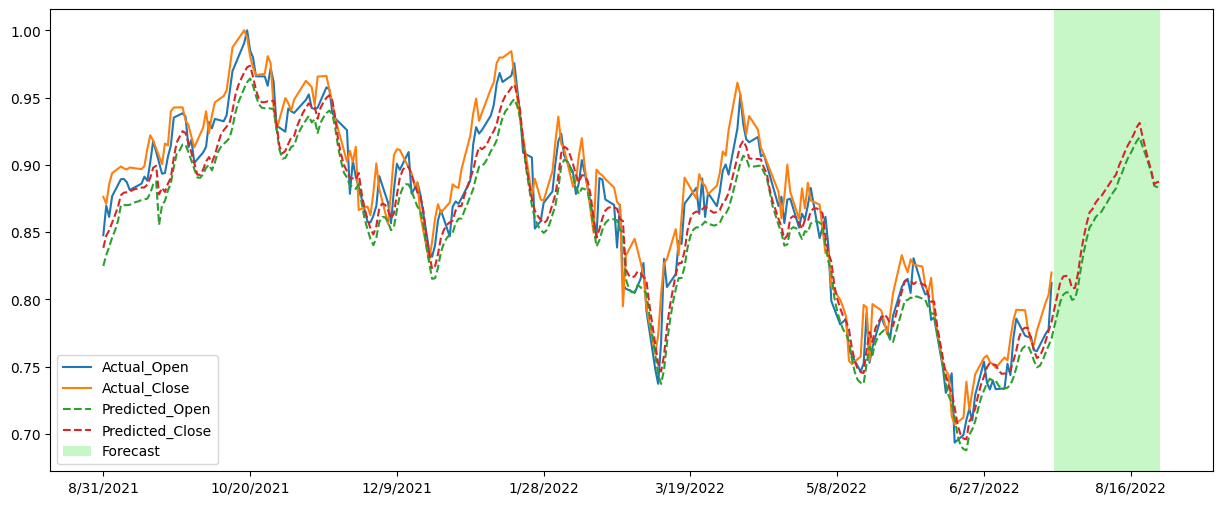

In [38]:
predicted_values = mv.predict(X_test)

d = {'Predicted_Open': predicted_values[:, 0],
'Predicted_Close': predicted_values[:,1],
'Actual_Open': y_test[:,0],
'Actual_Close': y_test[:,1]}

d = pd.DataFrame(d)
d.index = df.index[-len(y_test):]

fig, ax = plt.subplots(figsize=(15, 6))

highlight_start = int(len(d) * 0.9)
highlight_end = len(d) - 1

plt.plot(d[['Actual_Open', 'Actual_Close']][:highlight_start], label=['Actual_Open', 'Actual_Close'])
plt.plot(d[['Predicted_Open', 'Predicted_Close']], label=['Predicted_Open', 'Predicted_Close'], linestyle='--')
plt.axvspan(d.index[highlight_start], d.index[highlight_end], facecolor='lightgreen', alpha=0.5, label='Forecast')
plt.xticks(d.index[::50])
ax.legend()
plt.show()

In [39]:
print('Predicted Open: MSE=', sklearn.metrics.mean_squared_error(d[f'Actual_Open'], d['Predicted_Open']))
print('Predicted Open: MAE=', sklearn.metrics.mean_absolute_error(d[f'Actual_Open'], d['Predicted_Open']))
print('Predicted Open: R2=', sklearn.metrics.r2_score(d[f'Actual_Open'], d['Predicted_Open']))
print('Predicted Close: MSE=', sklearn.metrics.mean_squared_error(d[f'Actual_Close'], d['Predicted_Close']))
print('Predicted Close: MAE=', sklearn.metrics.mean_absolute_error(d[f'Actual_Close'], d['Predicted_Close']))
print('Predicted Close: R2=', sklearn.metrics.r2_score(d[f'Actual_Close'], d['Predicted_Close']))

Predicted Open: MSE= 0.00046616852705107063
Predicted Open: MAE= 0.018352329707611113
Predicted Open: R2= 0.896724252548035
Predicted Close: MSE= 0.0006021053583009462
Predicted Close: MAE= 0.020571861057267125
Predicted Close: R2= 0.862816643247144
